In [1]:
%pip install pandas numpy matplotlib seaborn openpyxl scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import glob
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles available in this folder:")
print(os.listdir())

Current working directory:
C:\Users\Sasank Bavirisetti\YuvaIntern

Files available in this folder:
['.git', '.ipynb_checkpoints', '00_Data_Dictionary.xlsx', '01_Profile_Data.xlsx', '02_Technical_Skills.xlsx', '03_Practical_Experience.xlsx', '04_Learning_Certifications.xlsx', '05_Soft_Skills_Readiness.xlsx', '06_Role_Requirements.xlsx', '07_Career_Readiness.xlsx', 'average_career_readiness_by_education.png', 'average_career_readiness_by_role.png', 'average_technical_skill_by_role.png', 'average_technical_skill_gap.png', 'career_readiness_distribution.png', 'correlation_heatmap.png', 'education_distribution.png', 'Figure_10_Communication_vs_Career_Readiness.png', 'Figure_11_Correlation_Heatmap.png', 'Figure_12_Role_Skill_Heatmap.png', 'Figure_13_Skill_Gap_Analysis.png', 'Figure_14_Technical_Skill_vs_Career_Readiness_by_Role.png', 'Figure_5_Learning_Hours_vs_Career_Readiness.png', 'Figure_6_Experience_vs_Career_Readiness.png', 'Figure_7_Education_vs_Career_Readiness.png', 'Figure_8_Prefer

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Your current working directory already contains the datasets
DATA_FOLDER = os.getcwd()

# Load all eight datasets
data_dictionary = pd.read_excel(
    os.path.join(DATA_FOLDER, "00_Data_Dictionary.xlsx")
)
profile_data = pd.read_excel(
    os.path.join(DATA_FOLDER, "01_Profile_Data.xlsx")
)
technical_skills = pd.read_excel(
    os.path.join(DATA_FOLDER, "02_Technical_Skills.xlsx")
)
practical_experience = pd.read_excel(
    os.path.join(DATA_FOLDER, "03_Practical_Experience.xlsx")
)
learning_certifications = pd.read_excel(
    os.path.join(DATA_FOLDER, "04_Learning_Certifications.xlsx")
)
soft_skills = pd.read_excel(
    os.path.join(DATA_FOLDER, "05_Soft_Skills_Readiness.xlsx")
)
role_requirements = pd.read_excel(
    os.path.join(DATA_FOLDER, "06_Role_Requirements.xlsx")
)
career_readiness = pd.read_excel(
    os.path.join(DATA_FOLDER, "07_Career_Readiness.xlsx")
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [5]:
datasets = {
    "Data Dictionary": data_dictionary,
    "Profile Data": profile_data,
    "Technical Skills": technical_skills,
    "Practical Experience": practical_experience,
    "Learning & Certifications": learning_certifications,
    "Soft Skills": soft_skills,
    "Role Requirements": role_requirements,
    "Career Readiness": career_readiness
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())


Data Dictionary
Shape: (28, 6)
Columns: ['File', 'Column', 'Description', 'Data Type', 'Example', 'Rule']

Profile Data
Shape: (501, 9)
Columns: ['Profile_ID', 'Age', 'Gender', 'Education', 'Graduation_Year', 'Experience_Years', 'Preferred_Role', 'Location_Type', 'Employment_Status']

Technical Skills
Shape: (4000, 3)
Columns: ['Profile_ID', 'Skill', 'Skill_Score']

Practical Experience
Shape: (500, 8)
Columns: ['Profile_ID', 'Projects_Completed', 'Major_Project_Completed', 'Project_Complexity', 'Internship_Completed', 'Internship_Months', 'Team_Project_Experience', 'GitHub_Activity']

Learning & Certifications
Shape: (500, 7)
Columns: ['Profile_ID', 'Learning_Hours_Per_Week', 'Online_Courses_Completed', 'Certifications_Count', 'Technical_Reading_Hours_Per_Week', 'Recent_Learning_Days', 'Mock_Interview_Sessions']

Soft Skills
Shape: (500, 6)
Columns: ['Profile_ID', 'Communication_Score', 'Problem_Solving_Score', 'Teamwork_Score', 'Interview_Readiness_Score', 'Resume_Readiness_Score']


In [6]:
# 1. Check duplicate rows and missing values in every dataset

quality_report = []

for name, df in datasets.items():
    quality_report.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Duplicate_Rows": df.duplicated().sum(),
        "Missing_Cells": df.isna().sum().sum(),
        "Missing_Columns": ", ".join(
            df.columns[df.isna().any()].tolist()
        )
    })

quality_df = pd.DataFrame(quality_report)

display(quality_df)

,Dataset,Rows,Columns,Duplicate_Rows,Missing_Cells,Missing_Columns
0,Data Dictionary,28,6,0,0,
1,Profile Data,501,9,1,0,
2,Technical Skills,4000,3,0,12,Skill_Score
3,Practical Experience,500,8,0,0,
4,Learning & Certifications,500,7,0,10,Learning_Hours_Per_Week
5,Soft Skills,500,6,0,10,Communication_Score
6,Role Requirements,64,3,0,0,
7,Career Readiness,500,10,0,0,


In [7]:
print("Total profile rows:", len(profile_data))
print("Unique Profile IDs:", profile_data["Profile_ID"].nunique())
print("Duplicate Profile IDs:",
      profile_data["Profile_ID"].duplicated().sum())

duplicate_profiles = profile_data[
    profile_data["Profile_ID"].duplicated(keep=False)
].sort_values("Profile_ID")

display(duplicate_profiles)

Total profile rows: 501
Unique Profile IDs: 500
Duplicate Profile IDs: 1


,Profile_ID,Age,Gender,Education,Graduation_Year,Experience_Years,Preferred_Role,Location_Type,Employment_Status
10,IT0011,23,Male,B.Sc,2023,2.5,Full Stack Developer,Metro,Employed
500,IT0011,23,Male,B.Sc,2023,2.5,Full Stack Developer,Metro,Employed


In [8]:
# Missing values by dataset
for name, df in datasets.items():
    missing = df.isna().sum()
    missing = missing[missing > 0]

    if not missing.empty:
        print(f"\n{name}")
        display(missing.rename("Missing_Count").to_frame())

# Technical skill score range
print("\nTechnical Skill Score Summary")
display(technical_skills["Skill_Score"].describe())

# Career readiness score summary
print("\nCareer Readiness Score Summary")
display(career_readiness[
    ["Skill_Average", "Average_Skill_Gap",
     "Career_Readiness_Score"]
].describe())

# Career readiness categories
print("\nCareer Readiness Distribution")
display(
    career_readiness["Career_Readiness_Level"]
    .value_counts(dropna=False)
    .rename_axis("Readiness_Level")
    .reset_index(name="Profile_Count")
)


Technical Skills


,Missing_Count
Skill_Score,12



Learning & Certifications


,Missing_Count
Learning_Hours_Per_Week,10



Soft Skills


...

count    3988.000000
mean       66.885657
std        17.661746
min         3.000000
25%        55.000000
50%        67.500000
75%        79.000000
max       100.000000
Name: Skill_Score, dtype: float64


Career Readiness Score Summary


,Skill_Average,Average_Skill_Gap,Career_Readiness_Score
count,500.000000,500.000000,500.000000
mean,66.859400,3.668140,60.671700
std,13.665701,4.890593,9.787738
min,16.500000,0.000000,28.450000
25%,57.590000,0.120000,54.700000
50%,67.380000,2.000000,61.355000
75%,75.685000,5.120000,68.075000
max,97.250000,29.120000,85.160000



Career Readiness Distribution


,Readiness_Level,Profile_Count
0,Developing,337
1,Job-Ready Level,106
2,Needs Development,56
3,Strong Readiness,1


,Readiness_Level,Profile_Count,Percentage
0,Developing,337,67.4
1,Job-Ready Level,106,21.2
2,Needs Development,56,11.2
3,Strong Readiness,1,0.2


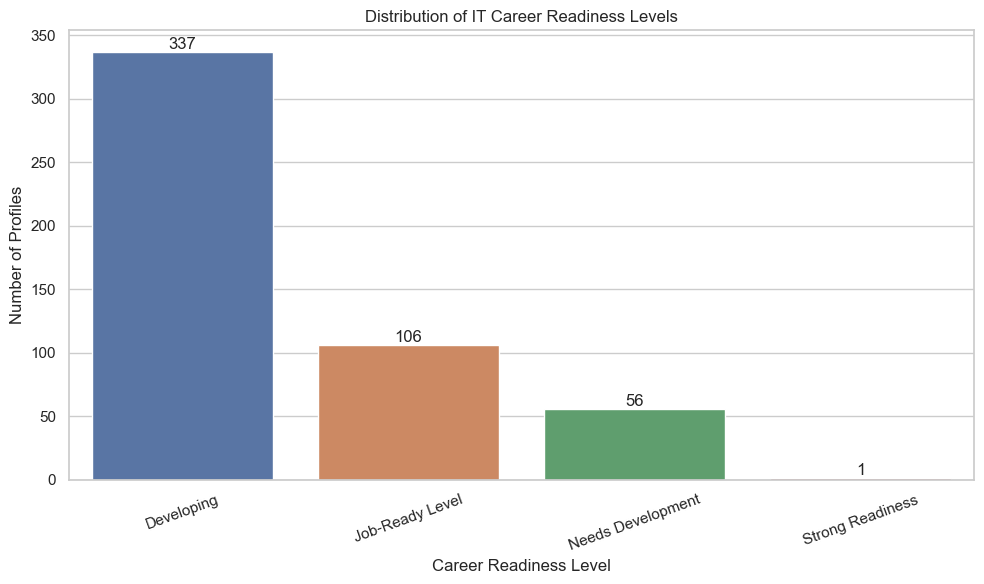

In [9]:
readiness_counts = (
    career_readiness["Career_Readiness_Level"]
    .value_counts()
    .reset_index()
)

readiness_counts.columns = ["Readiness_Level", "Profile_Count"]
readiness_counts["Percentage"] = (
    readiness_counts["Profile_Count"]
    / readiness_counts["Profile_Count"].sum() * 100
)

display(readiness_counts)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=readiness_counts,
    x="Readiness_Level",
    y="Profile_Count"
)

plt.title("Distribution of IT Career Readiness Levels")
plt.xlabel("Career Readiness Level")
plt.ylabel("Number of Profiles")
plt.xticks(rotation=20)

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig("week4_readiness_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
# Create separate copies; preserve the original datasets

profile_clean = profile_data.drop_duplicates().copy()

technical_clean = technical_skills.copy()
experience_clean = practical_experience.copy()
learning_clean = learning_certifications.copy()
soft_skills_clean = soft_skills.copy()
requirements_clean = role_requirements.copy()
readiness_clean = career_readiness.copy()

print("Original profile rows:", len(profile_data))
print("Cleaned profile rows:", len(profile_clean))
print("Unique profile IDs:", profile_clean["Profile_ID"].nunique())

print("\nMissing values after copying:")
print("Technical skill scores:", technical_clean["Skill_Score"].isna().sum())
print("Learning hours:", learning_clean["Learning_Hours_Per_Week"].isna().sum())
print("Communication scores:", soft_skills_clean["Communication_Score"].isna().sum())

Original profile rows: 501
Cleaned profile rows: 500
Unique profile IDs: 500

Missing values after copying:
Technical skill scores: 12
Learning hours: 10
Communication scores: 10


In [12]:
# Calculate average technical skill scores

skill_summary = (
    technical_clean
    .groupby("Skill")
    .agg(
        Average_Skill_Score=("Skill_Score", "mean"),
        Profiles_With_Scores=("Skill_Score", "count")
    )
    .reset_index()
)

# Count missing scores for each skill
missing_by_skill = (
    technical_clean
    .groupby("Skill")["Skill_Score"]
    .apply(lambda x: x.isna().sum())
    .reset_index(name="Missing_Scores")
)

# Combine the summaries
skill_summary = skill_summary.merge(
    missing_by_skill,
    on="Skill",
    how="left"
)

# Round the average scores
skill_summary["Average_Skill_Score"] = (
    skill_summary["Average_Skill_Score"].round(2)
)

# Sort from lowest to highest average score
skill_summary = skill_summary.sort_values(
    "Average_Skill_Score",
    ascending=True
)

display(skill_summary)

,Skill,Average_Skill_Score,Profiles_With_Scores,Missing_Scores
6,React,62.57,500,0
4,Power_BI,64.51,488,12
3,JavaScript,64.66,500,0
1,Excel,66.77,500,0
0,Cloud,67.41,500,0
2,Git,68.38,500,0
7,SQL,70.22,500,0
5,Python,70.52,500,0


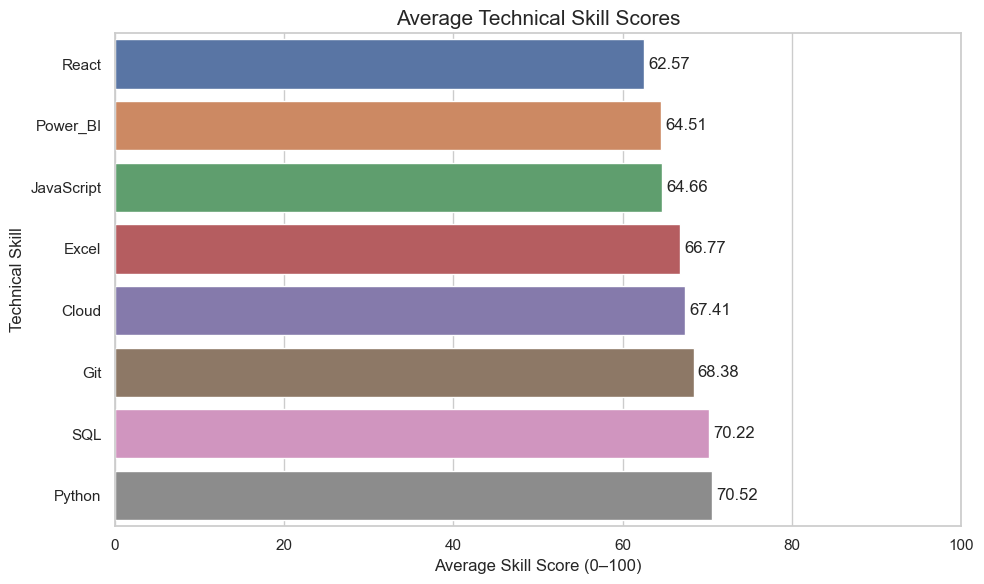

In [13]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=skill_summary,
    x="Average_Skill_Score",
    y="Skill"
)

plt.title("Average Technical Skill Scores", fontsize=15)
plt.xlabel("Average Skill Score (0–100)")
plt.ylabel("Technical Skill")
plt.xlim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.savefig(
    "week4_average_technical_skill_scores.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [14]:
print("Required skill levels:")
print(role_requirements["Required_Skill_Level"].dtype)

display(
    role_requirements["Required_Skill_Level"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nSummary statistics:")
display(role_requirements["Required_Skill_Level"].describe())

print("\nExample role requirements:")
display(role_requirements.head(12))

Required skill levels:
int64


10    3
15    5
20    8
25    3
30    4
35    3
40    1
45    3
50    1
55    4
60    2
65    3
70    7
75    5
80    5
85    5
90    2
Name: Required_Skill_Level, dtype: int64


Summary statistics:


count    64.000000
mean     49.921875
std      26.178450
min      10.000000
25%      23.750000
50%      55.000000
75%      75.000000
max      90.000000
Name: Required_Skill_Level, dtype: float64


Example role requirements:


,Preferred_Role,Skill,Required_Skill_Level
0,Data Analyst,Python,70
1,Data Analyst,SQL,75
2,Data Analyst,Excel,80
3,Data Analyst,Power_BI,75
4,Data Analyst,JavaScript,30
5,Data Analyst,React,20
6,Data Analyst,Cloud,35
7,Data Analyst,Git,45
8,Business Analyst,Python,50
9,Business Analyst,SQL,65


In [15]:
# Join preferred role information to technical skill records
profile_role = profile_clean[["Profile_ID", "Preferred_Role"]].drop_duplicates()

role_skill_data = technical_clean.merge(
    profile_role,
    on="Profile_ID",
    how="inner"
)

average_skill_by_role = (
    role_skill_data
    .groupby(["Preferred_Role", "Skill"])["Skill_Score"]
    .mean()
    .reset_index(name="Average_Skill_Score")
)

display(
    average_skill_by_role.sort_values(
        ["Preferred_Role", "Average_Skill_Score"]
    )
)

,Preferred_Role,Skill,Average_Skill_Score
1,AI/ML Engineer,Excel,57.480000
3,AI/ML Engineer,JavaScript,58.600000
6,AI/ML Engineer,React,58.920000
4,AI/ML Engineer,Power_BI,61.880000
0,AI/ML Engineer,Cloud,70.920000
2,AI/ML Engineer,Git,72.760000
7,AI/ML Engineer,SQL,73.400000
5,AI/ML Engineer,Python,81.400000
14,Business Analyst,React,48.892308
11,Business Analyst,JavaScript,54.169231


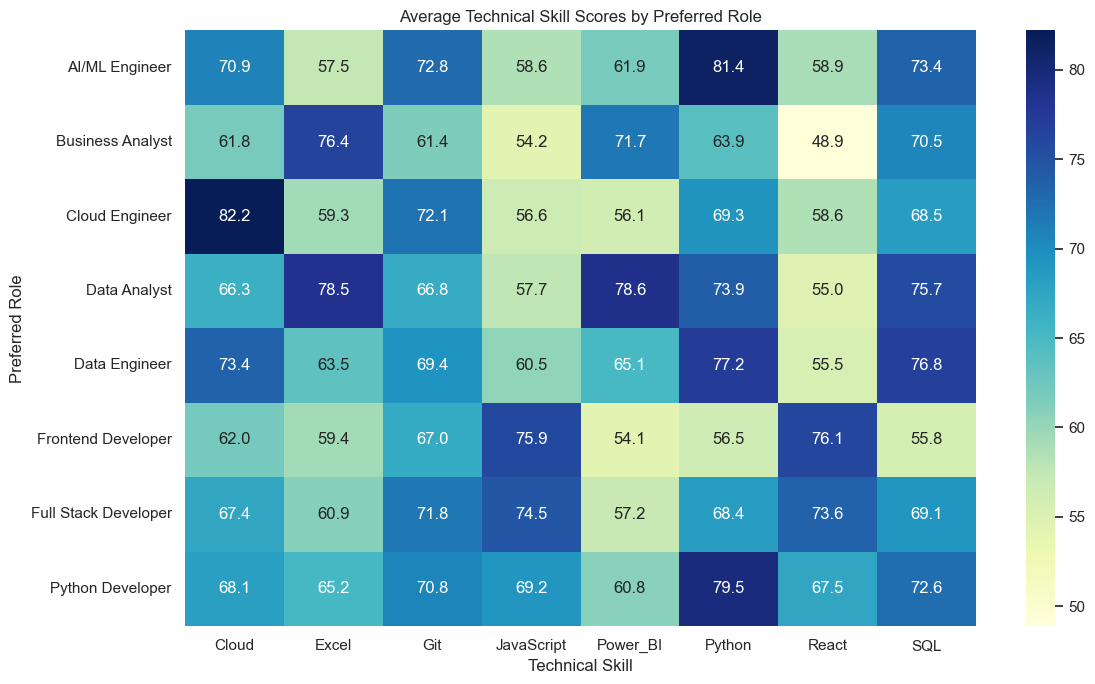

In [16]:
skill_pivot = average_skill_by_role.pivot(
    index="Preferred_Role",
    columns="Skill",
    values="Average_Skill_Score"
)

plt.figure(figsize=(12, 7))

sns.heatmap(
    skill_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Average Technical Skill Scores by Preferred Role")
plt.xlabel("Technical Skill")
plt.ylabel("Preferred Role")
plt.tight_layout()

plt.savefig(
    "week4_skill_scores_by_role.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
readiness_role_data = readiness_clean.merge(
    profile_clean[["Profile_ID", "Preferred_Role"]].drop_duplicates(),
    on="Profile_ID",
    how="left",
    suffixes=("", "_Profile")
)

# Prefer the role stored in the profile dataset
if "Preferred_Role_Profile" in readiness_role_data.columns:
    readiness_role_data["Preferred_Role"] = (
        readiness_role_data["Preferred_Role_Profile"]
        .fillna(readiness_role_data["Preferred_Role"])
    )

readiness_by_role = (
    readiness_role_data
    .groupby("Preferred_Role")
    .agg(
        Profile_Count=("Profile_ID", "nunique"),
        Average_Readiness_Score=("Career_Readiness_Score", "mean"),
        Average_Skill_Average=("Skill_Average", "mean"),
        Average_Skill_Gap=("Average_Skill_Gap", "mean")
    )
    .reset_index()
)

readiness_by_role[
    ["Average_Readiness_Score", "Average_Skill_Average", "Average_Skill_Gap"]
] = readiness_by_role[
    ["Average_Readiness_Score", "Average_Skill_Average", "Average_Skill_Gap"]
].round(2)

display(
    readiness_by_role.sort_values(
        "Average_Readiness_Score",
        ascending=False
    )
)

,Preferred_Role,Profile_Count,Average_Readiness_Score,Average_Skill_Average,Average_Skill_Gap
3,Data Analyst,95,62.57,69.04,2.91
0,AI/ML Engineer,25,62.04,66.92,2.79
7,Python Developer,73,61.45,69.20,2.88
6,Full Stack Developer,79,60.52,67.82,5.76
4,Data Engineer,64,60.50,67.73,4.50
1,Business Analyst,65,59.43,63.60,2.18
2,Cloud Engineer,24,59.15,65.33,3.76
5,Frontend Developer,75,58.92,63.35,4.03


In [18]:
# Calculate role-specific skill gaps

observed_skill_scores = (
    technical_clean
    .groupby("Skill")["Skill_Score"]
    .mean()
    .reset_index(name="Observed_Average_Score")
)

role_skill_gaps = requirements_clean.merge(
    observed_skill_scores,
    on="Skill",
    how="left"
)

role_skill_gaps["Skill_Gap"] = (
    role_skill_gaps["Required_Skill_Level"]
    - role_skill_gaps["Observed_Average_Score"]
)

# Positive = below requirement; negative = above requirement
role_skill_gaps["Gap_Status"] = np.where(
    role_skill_gaps["Skill_Gap"] > 0,
    "Below Requirement",
    np.where(
        role_skill_gaps["Skill_Gap"] < 0,
        "Above Requirement",
        "At Requirement"
    )
)

role_skill_gaps["Skill_Gap"] = role_skill_gaps["Skill_Gap"].round(2)

display(
    role_skill_gaps.sort_values(
        ["Preferred_Role", "Skill_Gap"],
        ascending=[True, False]
    )
)

,Preferred_Role,Skill,Required_Skill_Level,Observed_Average_Score,Skill_Gap,Gap_Status
48,AI/ML Engineer,Python,90,70.516000,19.48,Below Requirement
55,AI/ML Engineer,Git,70,68.378000,1.62,Below Requirement
54,AI/ML Engineer,Cloud,65,67.410000,-2.41,Above Requirement
49,AI/ML Engineer,SQL,65,70.220000,-5.22,Above Requirement
52,AI/ML Engineer,JavaScript,20,64.660000,-44.66,Above Requirement
50,AI/ML Engineer,Excel,20,66.772000,-46.77,Above Requirement
51,AI/ML Engineer,Power_BI,15,64.506148,-49.51,Above Requirement
53,AI/ML Engineer,React,10,62.566000,-52.57,Above Requirement
10,Business Analyst,Excel,80,66.772000,13.23,Below Requirement
11,Business Analyst,Power_BI,70,64.506148,5.49,Below Requirement


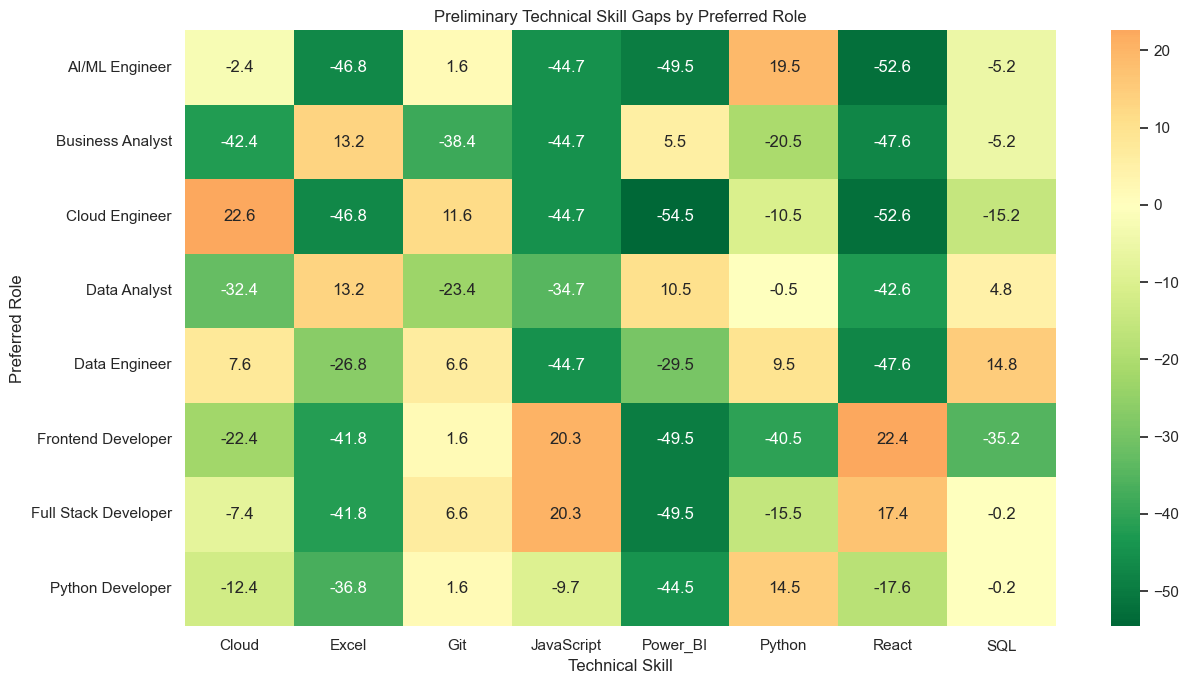

In [19]:
gap_pivot = role_skill_gaps.pivot(
    index="Preferred_Role",
    columns="Skill",
    values="Skill_Gap"
)

plt.figure(figsize=(13, 7))

sns.heatmap(
    gap_pivot,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    center=0
)

plt.title("Preliminary Technical Skill Gaps by Preferred Role")
plt.xlabel("Technical Skill")
plt.ylabel("Preferred Role")
plt.tight_layout()

plt.savefig(
    "week4_role_skill_gap_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
learning_analysis = learning_clean.merge(
    readiness_clean[
        ["Profile_ID", "Career_Readiness_Score", "Career_Readiness_Level"]
    ],
    on="Profile_ID",
    how="inner"
)

print("Learning hours summary:")
display(learning_analysis["Learning_Hours_Per_Week"].describe())

learning_groups = pd.cut(
    learning_analysis["Learning_Hours_Per_Week"],
    bins=[-0.1, 5, 10, 15, 25, float("inf")],
    labels=["0–5", "6–10", "11–15", "16–25", "Above 25"]
)

learning_readiness_summary = (
    learning_analysis.assign(Learning_Hours_Group=learning_groups)
    .groupby("Learning_Hours_Group", observed=False)
    .agg(
        Profile_Count=("Profile_ID", "nunique"),
        Average_Readiness=("Career_Readiness_Score", "mean")
    )
    .reset_index()
)

learning_readiness_summary["Average_Readiness"] = (
    learning_readiness_summary["Average_Readiness"].round(2)
)

display(learning_readiness_summary)

Learning hours summary:


count    490.000000
mean       7.964082
std        4.563420
min        0.000000
25%        5.225000
50%        7.900000
75%       10.300000
max       45.000000
Name: Learning_Hours_Per_Week, dtype: float64

,Learning_Hours_Group,Profile_Count,Average_Readiness
0,0–5,112,60.16
1,6–10,248,61.17
2,11–15,113,59.38
3,16–25,14,62.43
4,Above 25,3,70.44


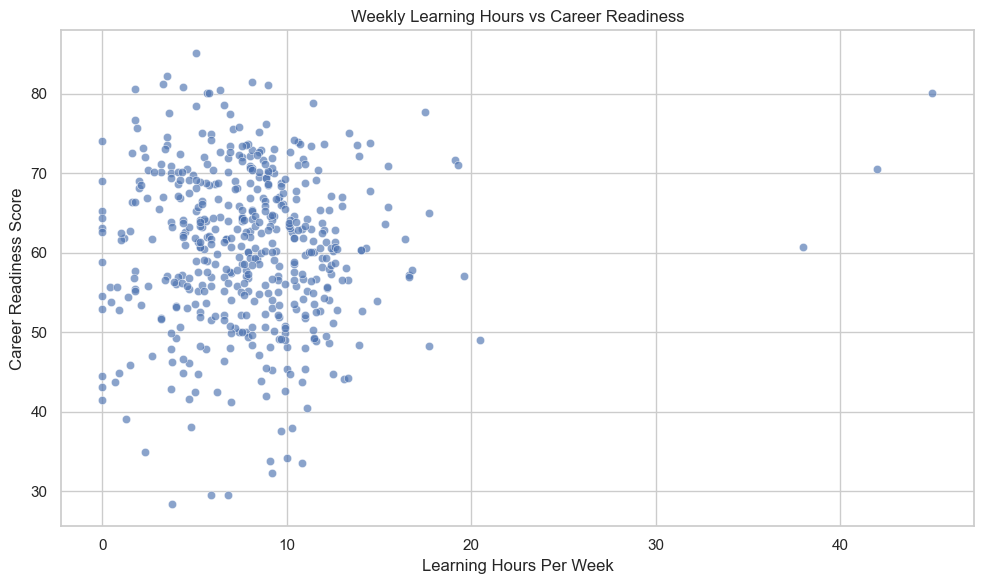

In [21]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=learning_analysis,
    x="Learning_Hours_Per_Week",
    y="Career_Readiness_Score",
    alpha=0.65
)

plt.title("Weekly Learning Hours vs Career Readiness")
plt.xlabel("Learning Hours Per Week")
plt.ylabel("Career Readiness Score")
plt.tight_layout()

plt.savefig(
    "week4_learning_hours_vs_readiness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
# Combine practical experience with career readiness

experience_analysis = experience_clean.merge(
    readiness_clean[
        ["Profile_ID", "Career_Readiness_Score", "Career_Readiness_Level"]
    ],
    on="Profile_ID",
    how="inner",
    validate="one_to_one"
)

print("Experience dataset shape:", experience_analysis.shape)

display(experience_analysis.head())

Experience dataset shape: (500, 10)


,Profile_ID,Projects_Completed,Major_Project_Completed,Project_Complexity,Internship_Completed,Internship_Months,Team_Project_Experience,GitHub_Activity,Career_Readiness_Score,Career_Readiness_Level
0,IT0001,5,Yes,Intermediate,Yes,6,No,16,64.56,Developing
1,IT0002,5,Yes,Intermediate,No,0,Yes,21,70.08,Job-Ready Level
2,IT0003,2,Yes,Intermediate,No,0,Yes,16,59.42,Developing
3,IT0004,1,Yes,Advanced,No,0,No,24,50.07,Developing
4,IT0005,3,No,Advanced,No,0,Yes,20,48.37,Needs Development


In [23]:
experience_columns = [
    "Projects_Completed",
    "Major_Project_Completed",
    "Project_Complexity",
    "Internship_Completed",
    "Internship_Months",
    "Team_Project_Experience",
    "GitHub_Activity"
]

for column in experience_columns:
    print(f"\nCareer readiness by {column}")

    summary = (
        experience_analysis
        .groupby(column, dropna=False)
        .agg(
            Profile_Count=("Profile_ID", "nunique"),
            Average_Readiness=("Career_Readiness_Score", "mean")
        )
        .reset_index()
    )

    summary["Average_Readiness"] = summary[
        "Average_Readiness"
    ].round(2)

    display(summary)


Career readiness by Projects_Completed


,Projects_Completed,Profile_Count,Average_Readiness
0,0,27,57.11
1,1,60,57.71
2,2,97,60.48
3,3,103,58.97
4,4,94,61.38
5,5,64,63.06
6,6,35,64.56
7,7,13,65.86
8,8,5,68.40
9,9,1,73.68



Career readiness by Major_Project_Completed


,Major_Project_Completed,Profile_Count,Average_Readiness
0,No,134,61.89
1,Yes,366,60.23



Career readiness by Project_Complexity


...

,Internship_Months,Profile_Count,Average_Readiness
0,0,240,58.73
1,1,16,66.99
2,2,21,63.90
3,3,32,60.19
4,4,40,63.09
5,5,42,60.38
6,6,37,62.02
7,7,21,62.28
8,8,24,63.52
9,9,11,63.30



Career readiness by Team_Project_Experience


,Team_Project_Experience,Profile_Count,Average_Readiness
0,No,149,60.32
1,Yes,351,60.82



Career readiness by GitHub_Activity


,GitHub_Activity,Profile_Count,Average_Readiness
0,7,3,62.82
1,8,2,54.78
2,9,2,59.29
3,10,4,60.38
4,11,13,58.59
5,12,13,57.19
6,13,22,59.81
7,14,34,58.38
8,15,43,62.93
9,16,46,63.62


In [25]:
# Select the required columns
soft_score_columns = [
    "Communication_Score",
    "Problem_Solving_Score",
    "Teamwork_Score",
    "Interview_Readiness_Score",
    "Resume_Readiness_Score"
]

correlation_columns = (
    soft_score_columns + ["Career_Readiness_Score"]
)

# Convert selected columns to numeric values
for column in correlation_columns:
    soft_analysis[column] = pd.to_numeric(
        soft_analysis[column],
        errors="coerce"
    )

# Calculate correlations
soft_summary = soft_analysis[
    correlation_columns
].corr()

display(soft_summary.round(2))

,Communication_Score,Problem_Solving_Score,Teamwork_Score,Interview_Readiness_Score,Resume_Readiness_Score,Career_Readiness_Score
Communication_Score,1.00,0.04,-0.03,-0.00,0.06,0.04
Problem_Solving_Score,0.04,1.00,-0.08,-0.01,0.07,0.14
Teamwork_Score,-0.03,-0.08,1.00,0.00,-0.03,-0.01
Interview_Readiness_Score,-0.00,-0.01,0.00,1.00,0.05,0.16
Resume_Readiness_Score,0.06,0.07,-0.03,0.05,1.00,0.12
Career_Readiness_Score,0.04,0.14,-0.01,0.16,0.12,1.00


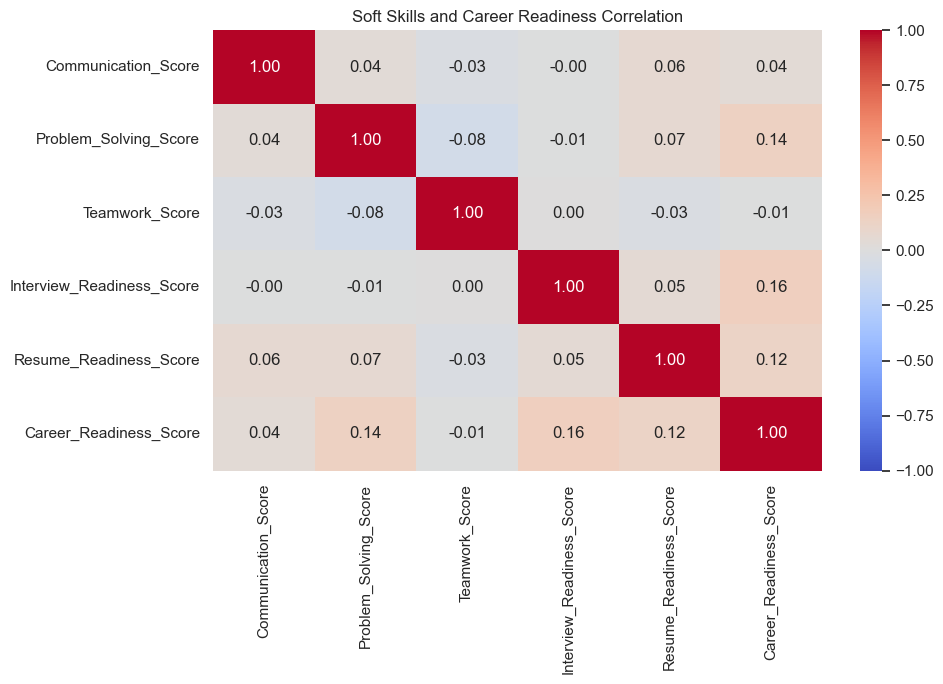

In [26]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    soft_summary,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Soft Skills and Career Readiness Correlation")
plt.tight_layout()

plt.savefig(
    "week4_soft_skills_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
# Combine practical experience and career readiness
experience_analysis = experience_clean.merge(
    readiness_clean[
        ["Profile_ID", "Career_Readiness_Score", "Career_Readiness_Level"]
    ],
    on="Profile_ID",
    how="inner"
)

# Summarize readiness by internship completion
internship_summary = (
    experience_analysis
    .groupby("Internship_Completed", dropna=False)
    .agg(
        Profile_Count=("Profile_ID", "nunique"),
        Average_Readiness=("Career_Readiness_Score", "mean")
    )
    .reset_index()
)

internship_summary["Average_Readiness"] = (
    internship_summary["Average_Readiness"].round(2)
)

display(internship_summary)

,Internship_Completed,Profile_Count,Average_Readiness
0,No,218,57.99
1,Yes,282,62.74


In [28]:
project_summary = (
    experience_analysis
    .groupby("Projects_Completed", dropna=False)
    .agg(
        Profile_Count=("Profile_ID", "nunique"),
        Average_Readiness=("Career_Readiness_Score", "mean")
    )
    .reset_index()
    .sort_values("Projects_Completed")
)

project_summary["Average_Readiness"] = (
    project_summary["Average_Readiness"].round(2)
)

display(project_summary)

,Projects_Completed,Profile_Count,Average_Readiness
0,0,27,57.11
1,1,60,57.71
2,2,97,60.48
3,3,103,58.97
4,4,94,61.38
5,5,64,63.06
6,6,35,64.56
7,7,13,65.86
8,8,5,68.40
9,9,1,73.68


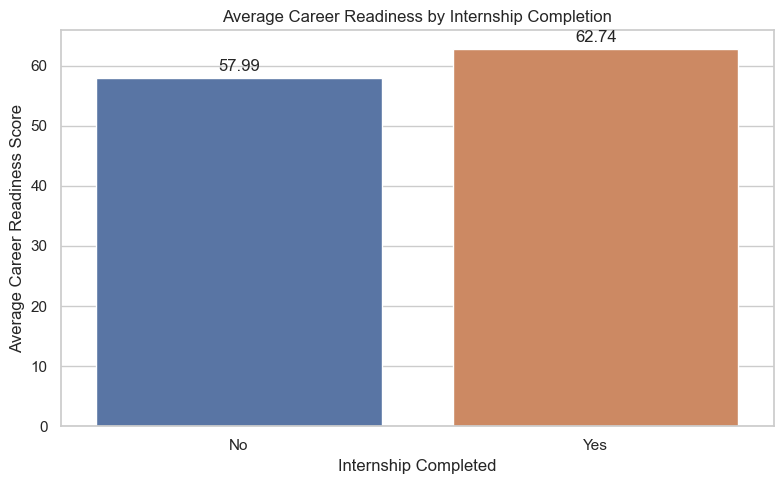

In [29]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=internship_summary,
    x="Internship_Completed",
    y="Average_Readiness"
)

plt.title("Average Career Readiness by Internship Completion")
plt.xlabel("Internship Completed")
plt.ylabel("Average Career Readiness Score")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.savefig(
    "week4_internship_vs_readiness.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [30]:
os.makedirs("outputs", exist_ok=True)

quality_df.to_csv("outputs/data_quality_report.csv", index=False)
skill_summary.to_csv("outputs/average_skill_scores.csv", index=False)
readiness_by_role.to_csv("outputs/readiness_by_role.csv", index=False)
role_skill_gaps.to_csv("outputs/preliminary_role_skill_gaps.csv", index=False)
soft_summary.to_csv("outputs/soft_skills_correlation.csv")

internship_summary.to_csv(
    "outputs/internship_vs_readiness.csv",
    index=False
)
project_summary.to_csv(
    "outputs/projects_vs_readiness.csv",
    index=False
)

print("Analysis results saved successfully!")

Analysis results saved successfully!


,Projects_Completed,Profile_Count,Average_Readiness
0,0,27,57.11
1,1,60,57.71
2,2,97,60.48
3,3,103,58.97
4,4,94,61.38
5,5,64,63.06
6,6,35,64.56
7,7,13,65.86
8,8,5,68.40
9,9,1,73.68


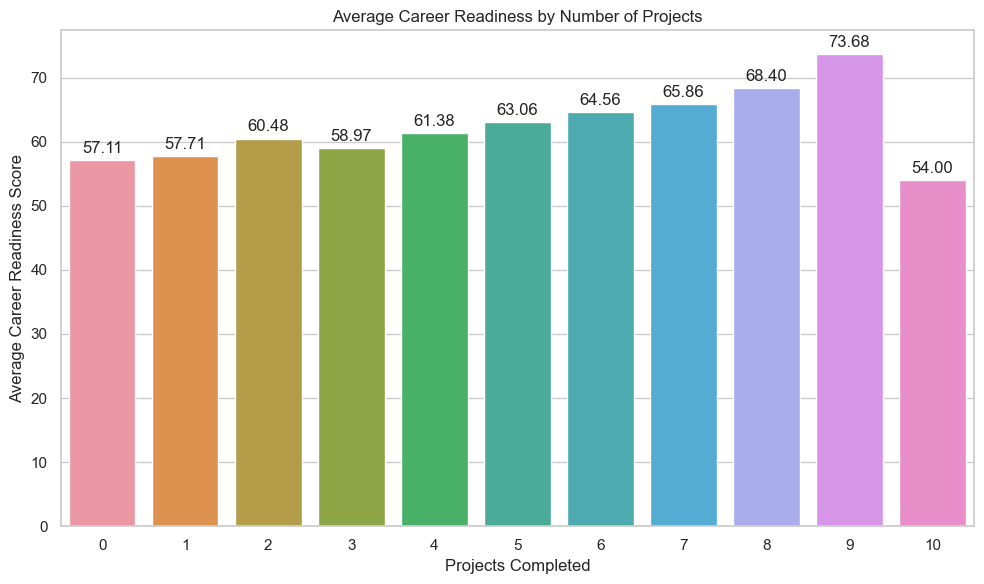

In [31]:
display(project_summary)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=project_summary,
    x="Projects_Completed",
    y="Average_Readiness"
)

plt.title("Average Career Readiness by Number of Projects")
plt.xlabel("Projects Completed")
plt.ylabel("Average Career Readiness Score")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.savefig(
    "week4_projects_vs_readiness.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [32]:
import os
import glob
import shutil

os.makedirs("outputs/charts", exist_ok=True)
os.makedirs("outputs/tables", exist_ok=True)

# Copy generated PNG charts
for file in glob.glob("week4_*.png"):
    shutil.copy2(file, os.path.join("outputs/charts", file))

# Save key analysis tables
tables = {
    "data_quality_report.csv": quality_df,
    "average_skill_scores.csv": skill_summary,
    "readiness_by_role.csv": readiness_by_role,
    "preliminary_role_skill_gaps.csv": role_skill_gaps,
    "soft_skills_correlation.csv": soft_summary,
    "internship_vs_readiness.csv": internship_summary,
    "projects_vs_readiness.csv": project_summary
}

for filename, table in tables.items():
    table.to_csv(os.path.join("outputs/tables", filename))

print("Charts and tables saved in outputs/")

Charts and tables saved in outputs/


In [33]:
project_summary = (
    experience_analysis
    .groupby("Projects_Completed", dropna=False)
    .agg(
        Profile_Count=("Profile_ID", "nunique"),
        Average_Readiness=("Career_Readiness_Score", "mean"),
        Median_Readiness=("Career_Readiness_Score", "median")
    )
    .reset_index()
    .sort_values("Projects_Completed")
)

project_summary[
    ["Average_Readiness", "Median_Readiness"]
] = project_summary[
    ["Average_Readiness", "Median_Readiness"]
].round(2)

display(project_summary)

,Projects_Completed,Profile_Count,Average_Readiness,Median_Readiness
0,0,27,57.11,57.65
1,1,60,57.71,56.15
2,2,97,60.48,60.20
3,3,103,58.97,60.08
4,4,94,61.38,62.24
5,5,64,63.06,63.14
6,6,35,64.56,65.89
7,7,13,65.86,64.43
8,8,5,68.40,70.98
9,9,1,73.68,73.68


In [34]:
# Rebuild the project summary with correctly aligned columns

project_summary = (
    experience_analysis
    .groupby("Projects_Completed", dropna=False)
    .agg(
        Profile_Count=("Profile_ID", "nunique"),
        Average_Readiness=("Career_Readiness_Score", "mean"),
        Median_Readiness=("Career_Readiness_Score", "median")
    )
    .reset_index()
    .sort_values("Projects_Completed")
)

project_summary["Average_Readiness"] = (
    project_summary["Average_Readiness"].round(2)
)
project_summary["Median_Readiness"] = (
    project_summary["Median_Readiness"].round(2)
)

display(project_summary)

,Projects_Completed,Profile_Count,Average_Readiness,Median_Readiness
0,0,27,57.11,57.65
1,1,60,57.71,56.15
2,2,97,60.48,60.20
3,3,103,58.97,60.08
4,4,94,61.38,62.24
5,5,64,63.06,63.14
6,6,35,64.56,65.89
7,7,13,65.86,64.43
8,8,5,68.40,70.98
9,9,1,73.68,73.68


In [35]:
# Calculate average skill scores for people targeting each role

role_skill_actual = (
    role_skill_data
    .groupby(["Preferred_Role", "Skill"])
    .agg(
        Profile_Count=("Profile_ID", "nunique"),
        Average_Observed_Score=("Skill_Score", "mean")
    )
    .reset_index()
)

# Match the actual averages with the requirements for each role
role_skill_final = requirements_clean.merge(
    role_skill_actual,
    on=["Preferred_Role", "Skill"],
    how="left"
)

role_skill_final["Skill_Gap"] = (
    role_skill_final["Required_Skill_Level"]
    - role_skill_final["Average_Observed_Score"]
)

role_skill_final["Skill_Gap"] = (
    role_skill_final["Skill_Gap"].round(2)
)

role_skill_final["Gap_Status"] = np.where(
    role_skill_final["Skill_Gap"] > 0,
    "Below Requirement",
    np.where(
        role_skill_final["Skill_Gap"] < 0,
        "Above Requirement",
        "At Requirement"
    )
)

display(
    role_skill_final.sort_values(
        ["Preferred_Role", "Skill_Gap"],
        ascending=[True, False]
    )
)

,Preferred_Role,Skill,Required_Skill_Level,Profile_Count,Average_Observed_Score,Skill_Gap,Gap_Status
48,AI/ML Engineer,Python,90,25,81.400000,8.60,Below Requirement
55,AI/ML Engineer,Git,70,25,72.760000,-2.76,Above Requirement
54,AI/ML Engineer,Cloud,65,25,70.920000,-5.92,Above Requirement
49,AI/ML Engineer,SQL,65,25,73.400000,-8.40,Above Requirement
50,AI/ML Engineer,Excel,20,25,57.480000,-37.48,Above Requirement
52,AI/ML Engineer,JavaScript,20,25,58.600000,-38.60,Above Requirement
51,AI/ML Engineer,Power_BI,15,25,61.880000,-46.88,Above Requirement
53,AI/ML Engineer,React,10,25,58.920000,-48.92,Above Requirement
10,Business Analyst,Excel,80,65,76.446154,3.55,Below Requirement
11,Business Analyst,Power_BI,70,65,71.671875,-1.67,Above Requirement


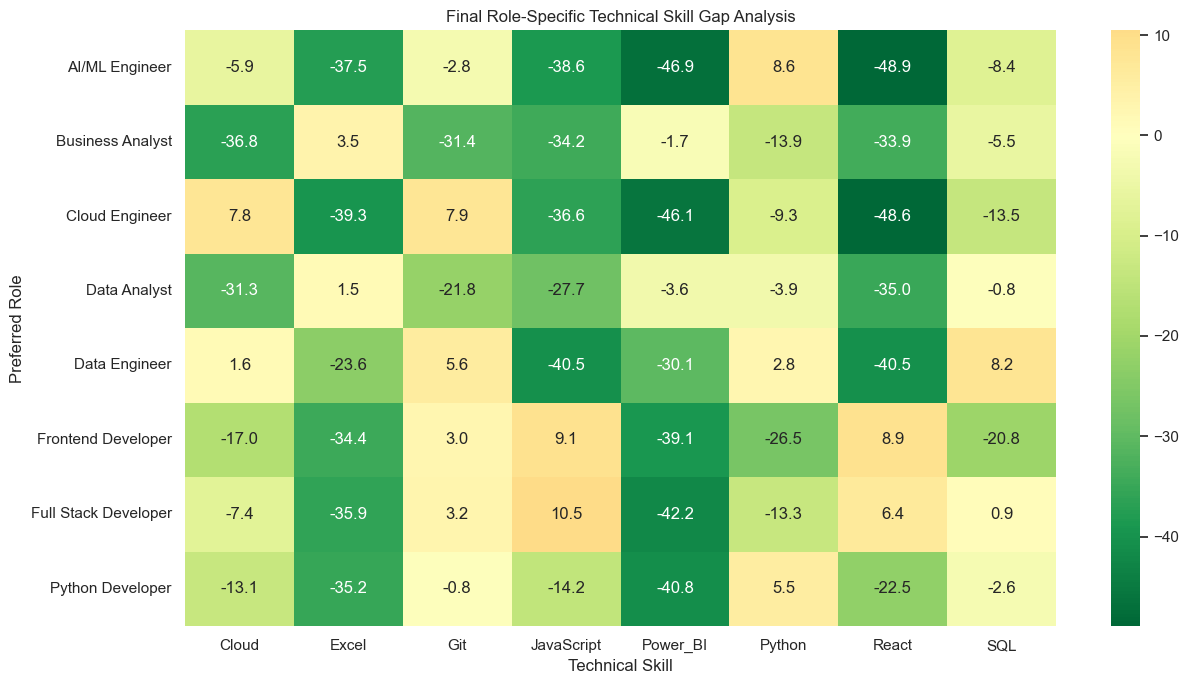

Final role-specific skill gaps saved successfully.


In [36]:
# Final role-specific skill-gap heatmap

role_gap_pivot = role_skill_final.pivot(
    index="Preferred_Role",
    columns="Skill",
    values="Skill_Gap"
)

plt.figure(figsize=(13, 7))

sns.heatmap(
    role_gap_pivot,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    center=0
)

plt.title("Final Role-Specific Technical Skill Gap Analysis")
plt.xlabel("Technical Skill")
plt.ylabel("Preferred Role")
plt.tight_layout()

plt.savefig(
    "week4_final_role_skill_gap_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

role_skill_final.to_csv(
    "outputs/final_role_skill_gaps.csv",
    index=False
)

print("Final role-specific skill gaps saved successfully.")

In [37]:
import os
import shutil

os.makedirs("outputs/charts", exist_ok=True)
os.makedirs("outputs/tables", exist_ok=True)

# Save the final role-specific skill-gap table
role_skill_final.to_csv(
    "outputs/tables/final_role_skill_gaps.csv",
    index=False
)

# Save the project summary
project_summary.to_csv(
    "outputs/tables/projects_vs_readiness.csv",
    index=False
)

# Save the final chart
shutil.copy2(
    "week4_final_role_skill_gap_heatmap.png",
    "outputs/charts/week4_final_role_skill_gap_heatmap.png"
)

print("Final outputs saved successfully!")

Final outputs saved successfully!
